# UCS420: Cognitive Computing — Assignment 10
## Diabetes Care Information Assistant

---
### Student Information
- **Student Name:** Dhruv Singla
- **Roll Number:** 1024160007
- **Batch:** 3P11

**Domain selection:** The roll number ends in 7 and is odd. Therefore, this assignment implements the **Diabetes Care Information Assistant** specified for odd roll numbers.

**Objective:** Develop a Python assistant that preprocesses queries, predicts an intent, applies reasoning rules, retrieves source-backed diabetes information, and responds through a repeatable interactive interface.

This is an educational information-retrieval prototype. It does not diagnose a person, prescribe treatment, or calculate medicine doses.

## 1. Run in Google Colab
1. Open [Google Colab](https://colab.research.google.com/), select **File → Upload notebook**, and upload this `.ipynb` file.
2. Select **Runtime → Run all**. A standard CPU runtime is enough.
3. In Section 10, enter a query and click **Ask**. Submit more queries in the same interface; **Clear history** clears the displayed conversation.
4. If widgets are unavailable, Section 10 also includes a console loop that accepts queries until `exit`.

The installation cell installs missing packages only. NLTK's WordNet dictionary downloads once into a local working directory. The corpus, taxonomy, knowledge base, training, tests and interface are all included in this notebook. No external API key, patient data or separate dataset file is required. Saved results were executed locally; upload and rerun to start a live Colab session.

In [1]:
import importlib.util
import subprocess
import sys

required = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
            'sklearn': 'scikit-learn', 'nltk': 'nltk', 'ipywidgets': 'ipywidgets'}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Required Python libraries are available.')

Required Python libraries are available.


In [2]:
import re
import json
import html
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.tokenize import RegexpTokenizer
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display, Markdown, HTML
import ipywidgets as widgets

SEED = 1024160007
assert SEED % 2 == 1
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})
pd.set_option('display.max_colwidth', 90)

nltk_dir = Path('assignment10_nltk_data')
nltk_dir.mkdir(exist_ok=True)
nltk.data.path.insert(0, str(nltk_dir.resolve()))
lemmatizer = WordNetLemmatizer()
try:
    lemmatizer.lemmatize('tablets')
except LookupError:
    if not nltk.download('wordnet', download_dir=str(nltk_dir), quiet=True):
        raise RuntimeError('WordNet download failed. Check internet access and rerun.')
    lemmatizer.lemmatize('tablets')
print('Dhruv Singla | 1024160007 | Diabetes Care Information Assistant')

Dhruv Singla | 1024160007 | Diabetes Care Information Assistant


## 2. Labelled Corpus: 128 Queries Across 8 Intents
The corpus below is an original, manually labelled educational dataset with **16 distinct queries per intent**. Queries contain no real patient records. Each query has one primary intent. Emergency and unsupported queries are deliberately handled by reasoning rules rather than being forced into these eight information intents.

The same word can occur in different intents: for example, laboratory diagnosis differs from day-to-day glucose monitoring. The classifier must use the surrounding words. This small corpus is suitable for demonstrating the workflow, not for establishing clinical reliability.

In [3]:
CORPUS = {'symptoms': ['What are common symptoms of diabetes?',
              'Which warning signs suggest diabetes?',
              'Can diabetes cause excessive thirst?',
              'Why do people with diabetes urinate frequently?',
              'Is unexplained weight loss a symptom of diabetes?',
              'Does diabetes make people feel tired?',
              'Can blurry vision be a sign of diabetes?',
              'What early symptoms should I watch for?',
              'Are slow healing wounds a warning sign?',
              'Can someone have diabetes without obvious symptoms?',
              'What physical signs occur with high blood sugar?',
              'Why might diabetes cause frequent hunger?',
              'Explain the usual signs of diabetes in adults.',
              'Could increased thirst be related to diabetes?',
              'What symptoms develop when blood glucose is high?',
              'Is frequent urination associated with diabetes?'],
 'diagnosis': ['Which tests are used to diagnose diabetes?',
               'How does a doctor diagnose diabetes?',
               'What is a fasting plasma glucose test?',
               'Explain the oral glucose tolerance test.',
               'How is an A1C blood test used for diagnosis?',
               'Do I need a laboratory test to confirm diabetes?',
               'Can a random plasma glucose test diagnose diabetes?',
               'Why might a diabetes diagnostic test be repeated?',
               'What happens during diabetes screening?',
               'Which blood tests confirm a diabetes diagnosis?',
               'Can my home meter alone establish a diagnosis?',
               'Who should discuss diabetes screening with a doctor?',
               'What laboratory investigations identify diabetes?',
               'How is prediabetes diagnosed with blood tests?',
               'What does HbA1c measure during screening?',
               'How do clinicians confirm a suspected diabetes diagnosis?'],
 'nutrition': ['What should a person with diabetes eat?',
               'How do carbohydrates affect blood sugar?',
               'Explain a balanced diabetes meal plan.',
               'What is the plate method for meals?',
               'Can I include fruit in a diabetes diet?',
               'Why is portion control useful for diabetes?',
               'Which drinks are better for a diabetes eating plan?',
               'How can I plan balanced meals with vegetables?',
               'What does carbohydrate counting mean?',
               'Should I discuss a meal plan with a dietitian?',
               'How can I choose high fiber foods?',
               'Explain healthy eating for blood sugar management.',
               'What are sensible food choices for diabetes?',
               'Can whole grains fit into a diabetes meal plan?',
               'Why do sugary beverages affect glucose?',
               'How can I balance carbohydrates and protein at meals?'],
 'physical_activity': ['How does exercise help people with diabetes?',
                       'Is walking useful for diabetes management?',
                       'What physical activities can support blood sugar control?',
                       'How can I become more physically active?',
                       'Can strength training be part of diabetes care?',
                       'Why should I discuss a new exercise plan with my clinician?',
                       'Can physical activity lower blood glucose?',
                       'How can I reduce long periods of sitting?',
                       'What precautions should I consider when exercising?',
                       'Can swimming be a suitable physical activity?',
                       'Explain the benefits of regular movement for diabetes.',
                       'How can I start a walking routine safely?',
                       'What should I know before starting workouts?',
                       'Can cycling support diabetes management?',
                       'How does resistance exercise affect diabetes care?',
                       'Why should glucose be considered around physical activity?'],
 'glucose_monitoring': ['How do I monitor my blood glucose at home?',
                        'What is a continuous glucose monitor?',
                        'How does a finger prick glucose meter work?',
                        'Why should I keep a blood sugar log?',
                        'When should I check my blood sugar each day?',
                        'How can I discuss glucose readings with my care team?',
                        'What does a CGM trend arrow represent?',
                        'Why do glucose targets differ between people?',
                        'How can I record daily glucose readings?',
                        'What supplies are needed for home glucose monitoring?',
                        'Why should I review blood sugar patterns?',
                        'How is home glucose tracking different from a lab diagnosis?',
                        'Explain checking sugar levels using a glucometer.',
                        'How do I share my glucose log with my doctor?',
                        'What can a glucose sensor tell me during the day?',
                        'Why might my care team recommend more frequent glucose checks?'],
 'medication': ['What is the role of insulin in diabetes treatment?',
                'Why is metformin used for type 2 diabetes?',
                'What kinds of medicines are used to treat diabetes?',
                'Why should diabetes medicines be taken as prescribed?',
                'Who decides which diabetes medication is appropriate?',
                'Can diabetes treatment include oral tablets?',
                'How do clinicians choose between diabetes medicines?',
                'Why might someone with diabetes need insulin?',
                'What should I discuss with a pharmacist about my medication?',
                'How can I learn about side effects of prescribed tablets?',
                'What factors influence diabetes medicine selection?',
                'What is the difference between insulin and oral medicines?',
                'Explain general treatment options for diabetes.',
                'Can treatment plans include injectable diabetes medicines?',
                'Why is medication adherence important in diabetes?',
                'How can medicine costs be discussed with the care team?'],
 'complications': ['What long term complications can diabetes cause?',
                   'How can diabetes affect the kidneys?',
                   'Why are regular eye checks important with diabetes?',
                   'Can diabetes damage nerves in the feet?',
                   'Why should people with diabetes check their feet?',
                   'How is diabetes related to heart disease?',
                   'What are possible effects of diabetes on blood vessels?',
                   'Why are kidney checks part of diabetes care?',
                   'What is diabetic neuropathy?',
                   'How can diabetes affect vision over time?',
                   'Why should a foot wound be reviewed promptly?',
                   'What health problems may follow persistently high glucose?',
                   'Explain diabetes related damage to organs.',
                   'Why should diabetes care include dental checks?',
                   'Can nerve damage cause reduced feeling in the feet?',
                   'How can follow up visits help detect diabetes complications?'],
 'prevention': ['How can type 2 diabetes be prevented or delayed?',
                'What steps reduce the risk of type 2 diabetes?',
                'Can lifestyle changes help people with prediabetes?',
                'What is a diabetes prevention programme?',
                'How does weight management affect diabetes risk?',
                'Can a family history increase diabetes risk?',
                'Who is at increased risk of developing type 2 diabetes?',
                'How can I discuss prevention with my doctor?',
                'Why is regular screening useful for people at risk?',
                'Can healthy habits delay type 2 diabetes?',
                'What are common risk factors for type 2 diabetes?',
                'Does a history of gestational diabetes affect future risk?',
                'How can people with prediabetes lower their future risk?',
                'Are age and family history diabetes risk factors?',
                'What does preventing progression from prediabetes involve?',
                'Can a structured lifestyle programme reduce future diabetes risk?']}

corpus_df = pd.DataFrame([{'query': query, 'intent': intent}
                          for intent, queries in CORPUS.items() for query in queries])
assert len(corpus_df) == 128
assert corpus_df['intent'].nunique() == 8
assert not corpus_df['query'].str.lower().duplicated().any()
print('Total labelled queries:', len(corpus_df))
display(corpus_df.groupby('intent').size().rename('queries').to_frame())
display(corpus_df.groupby('intent', sort=False).head(2).reset_index(drop=True))

Total labelled queries: 128


,queries
intent,
complications,16
diagnosis,16
glucose_monitoring,16
medication,16
nutrition,16
physical_activity,16
prevention,16
symptoms,16


,query,intent
0,What are common symptoms of diabetes?,symptoms
1,Which warning signs suggest diabetes?,symptoms
2,Which tests are used to diagnose diabetes?,diagnosis
3,How does a doctor diagnose diabetes?,diagnosis
4,What should a person with diabetes eat?,nutrition
5,How do carbohydrates affect blood sugar?,nutrition
6,How does exercise help people with diabetes?,physical_activity
7,Is walking useful for diabetes management?,physical_activity
8,How do I monitor my blood glucose at home?,glucose_monitoring
9,What is a continuous glucose monitor?,glucose_monitoring


## 3. Hierarchical Taxonomy
The hierarchy has **four major categories**, each containing **two subcategories**. The leaf names match the classifier labels exactly.

In [4]:
TAXONOMY = {
    'Understanding diabetes': {'Symptoms and warning signs': 'symptoms',
                              'Tests and diagnosis': 'diagnosis'},
    'Daily lifestyle': {'Food and meal planning': 'nutrition',
                       'Exercise and movement': 'physical_activity'},
    'Treatment and tracking': {'Home glucose monitoring': 'glucose_monitoring',
                              'Medicines and insulin': 'medication'},
    'Risk and long-term health': {'Complications and follow-up': 'complications',
                                'Prevention and risk factors': 'prevention'}
}
INTENT_PATH = {}
for major, children in TAXONOMY.items():
    print(major)
    for name, intent in children.items():
        INTENT_PATH[intent] = f'{major} → {name}'
        print(f'  └─ {name} [{intent}]')
assert len(TAXONOMY) >= 4 and all(len(v) >= 2 for v in TAXONOMY.values())
assert set(INTENT_PATH) == set(CORPUS)

Understanding diabetes
  └─ Symptoms and warning signs [symptoms]
  └─ Tests and diagnosis [diagnosis]
Daily lifestyle
  └─ Food and meal planning [nutrition]
  └─ Exercise and movement [physical_activity]
Treatment and tracking
  └─ Home glucose monitoring [glucose_monitoring]
  └─ Medicines and insulin [medication]
Risk and long-term health
  └─ Complications and follow-up [complications]
  └─ Prevention and risk factors [prevention]


## 4. Domain Concepts and Relationships
The explicit knowledge graph contains **15 concepts** and **16 directed relationships**. It records a small domain model rather than a causal model of a particular patient. A concept lookup is integrated into the assistant's explanation of a retrieved answer. Clinical relationships are summarized from the NIDDK and CDC sources listed in Section 7.

In [5]:
CONCEPTS = {
    'Diabetes': 'A condition involving problems regulating blood glucose.',
    'Blood glucose': 'Glucose circulating in the blood.',
    'Insulin': 'A hormone that helps glucose enter cells.',
    'A1C': 'A laboratory measure reflecting average blood glucose over recent months.',
    'Glucose meter': 'A device for checking a current blood glucose reading.',
    'CGM': 'A sensor system that estimates glucose in interstitial fluid over time.',
    'Nutrition': 'Food choices and meal planning considered in diabetes care.',
    'Physical activity': 'Body movement that can support glucose management.',
    'Medication': 'Prescribed treatment selected by a clinician.',
    'Hypoglycemia': 'Low blood glucose.',
    'Hyperglycemia': 'High blood glucose.',
    'Complications': 'Health problems that can affect organs and tissues.',
    'Prediabetes': 'Glucose above normal but below the diabetes diagnostic range.',
    'Type 2 diabetes': 'A diabetes type involving insulin resistance and other factors.',
    'Care team': 'Health professionals supporting individual diabetes care.'
}
RELATIONSHIPS = [
    ('Insulin', 'helps regulate', 'Blood glucose'),
    ('Diabetes', 'affects regulation of', 'Blood glucose'),
    ('A1C', 'summarizes recent average', 'Blood glucose'),
    ('Glucose meter', 'measures', 'Blood glucose'),
    ('CGM', 'tracks trends related to', 'Blood glucose'),
    ('Nutrition', 'influences', 'Blood glucose'),
    ('Physical activity', 'can help manage', 'Blood glucose'),
    ('Medication', 'can help manage', 'Diabetes'),
    ('Insulin', 'may be prescribed as', 'Medication'),
    ('Hypoglycemia', 'means low', 'Blood glucose'),
    ('Hyperglycemia', 'means high', 'Blood glucose'),
    ('Diabetes', 'can lead to', 'Complications'),
    ('Prediabetes', 'increases risk of', 'Type 2 diabetes'),
    ('Care team', 'individualizes', 'Medication'),
    ('Care team', 'supports', 'Nutrition'),
    ('Care team', 'helps plan', 'Physical activity')
]
assert len(CONCEPTS) >= 8 and len(RELATIONSHIPS) >= 10
assert all(a in CONCEPTS and b in CONCEPTS for a, _, b in RELATIONSHIPS)
display(pd.DataFrame(CONCEPTS.items(), columns=['Concept', 'Definition']))
display(pd.DataFrame(RELATIONSHIPS, columns=['Subject', 'Relationship', 'Object']))

def related_facts(concept, limit=3):
    return [f'{a} — {r} — {b}' for a, r, b in RELATIONSHIPS
            if a == concept or b == concept][:limit]

,Concept,Definition
0,Diabetes,A condition involving problems regulating blood glucose.
1,Blood glucose,Glucose circulating in the blood.
2,Insulin,A hormone that helps glucose enter cells.
3,A1C,A laboratory measure reflecting average blood glucose over recent months.
4,Glucose meter,A device for checking a current blood glucose reading.
5,CGM,A sensor system that estimates glucose in interstitial fluid over time.
6,Nutrition,Food choices and meal planning considered in diabetes care.
7,Physical activity,Body movement that can support glucose management.
8,Medication,Prescribed treatment selected by a clinician.
9,Hypoglycemia,Low blood glucose.


,Subject,Relationship,Object
0,Insulin,helps regulate,Blood glucose
1,Diabetes,affects regulation of,Blood glucose
2,A1C,summarizes recent average,Blood glucose
3,Glucose meter,measures,Blood glucose
4,CGM,tracks trends related to,Blood glucose
5,Nutrition,influences,Blood glucose
6,Physical activity,can help manage,Blood glucose
7,Medication,can help manage,Diabetes
8,Insulin,may be prescribed as,Medication
9,Hypoglycemia,means low,Blood glucose


## 5. NLP Preprocessing
Four required stages are implemented explicitly: **lowercasing → tokenization → stopword removal → lemmatization**. Regex tokenization keeps words and numbers without downloading a sentence tokenizer. Common English stopwords are removed, while negation words are retained. WordNet lemmatization is applied to verbs and then nouns, with diabetes-domain terms protected from inappropriate dictionary changes.

Emergency and dose rules inspect the original lowercased text before stopword removal. Retaining negations does not give this simple system full understanding of negated or hypothetical medical situations.

In [6]:
tokenizer = RegexpTokenizer(r"[a-z][a-z0-9]*(?:'[a-z]+)?|\d+(?:\.\d+)?")
STOP_WORDS = set(ENGLISH_STOP_WORDS) - {'no', 'not', 'never', 'without'}
PROTECTED = {'diabetes', 'prediabetes', 'insulin', 'metformin', 'glucose', 'a1c', 'hba1c', 'cgm'}

def preprocess_steps(text):
    lowercase = str(text).lower()
    tokens = tokenizer.tokenize(lowercase)
    filtered = [t for t in tokens if t not in STOP_WORDS]
    lemmas = [t if t in PROTECTED else lemmatizer.lemmatize(
              lemmatizer.lemmatize(t, pos='v'), pos='n') for t in filtered]
    return {'lowercase': lowercase, 'tokens': tokens,
            'stopwords_removed': filtered, 'lemmatized': lemmas}

def preprocess(text):
    return ' '.join(preprocess_steps(text)['lemmatized'])

example = 'The patients are checking their glucose levels and taking tablets.'
for stage, value in preprocess_steps(example).items():
    print(stage + ':', value)
assert 'diabetes' in preprocess('Diabetes symptoms')
assert 'not' in preprocess('I am not taking tablets')
assert 'a1c' in preprocess('A1C screening')
assert 'hba1c' in preprocess('HbA1c blood test')

lowercase: the patients are checking their glucose levels and taking tablets.
tokens: ['the', 'patients', 'are', 'checking', 'their', 'glucose', 'levels', 'and', 'taking', 'tablets']
stopwords_removed: ['patients', 'checking', 'glucose', 'levels', 'taking', 'tablets']
lemmatized: ['patient', 'check', 'glucose', 'level', 'take', 'tablet']


## 6. TF-IDF, Logistic Regression and Held-Out Evaluation
The corpus is split **with stratification into 72 training, 24 validation, and 32 test queries**, using the student's roll number as the seed. Each intent contributes 9 training, 3 validation, and 4 test queries. The test set is held out during fitting and threshold selection.

TF-IDF uses word unigrams and bigrams. The vocabulary and inverse-document-frequency values are fitted **only on training queries**, through a scikit-learn pipeline. Logistic regression predicts the eight intent labels. Its probability outputs are model scores, not validated clinical confidence.

Accuracy and macro-averaged precision, recall and F1 summarize the held-out classifier. The confusion matrix and per-class report reveal class-specific errors. We additionally compare with the majority-class baseline and report every misclassified test query.

Training / validation / test: 72 24 32
TF-IDF features: 389


,Accuracy,Macro precision,Macro recall,Macro F1
0,0.75,0.7979,0.75,0.7489


Majority-class baseline accuracy: 0.125

Per-intent classification report:
                    precision    recall  f1-score   support

     complications      0.750     0.750     0.750         4
         diagnosis      0.800     1.000     0.889         4
glucose_monitoring      0.667     1.000     0.800         4
        medication      1.000     0.500     0.667         4
         nutrition      1.000     0.750     0.857         4
 physical_activity      0.667     0.500     0.571         4
        prevention      0.500     0.750     0.600         4
          symptoms      1.000     0.750     0.857         4

          accuracy                          0.750        32
         macro avg      0.798     0.750     0.749        32
      weighted avg      0.798     0.750     0.749        32



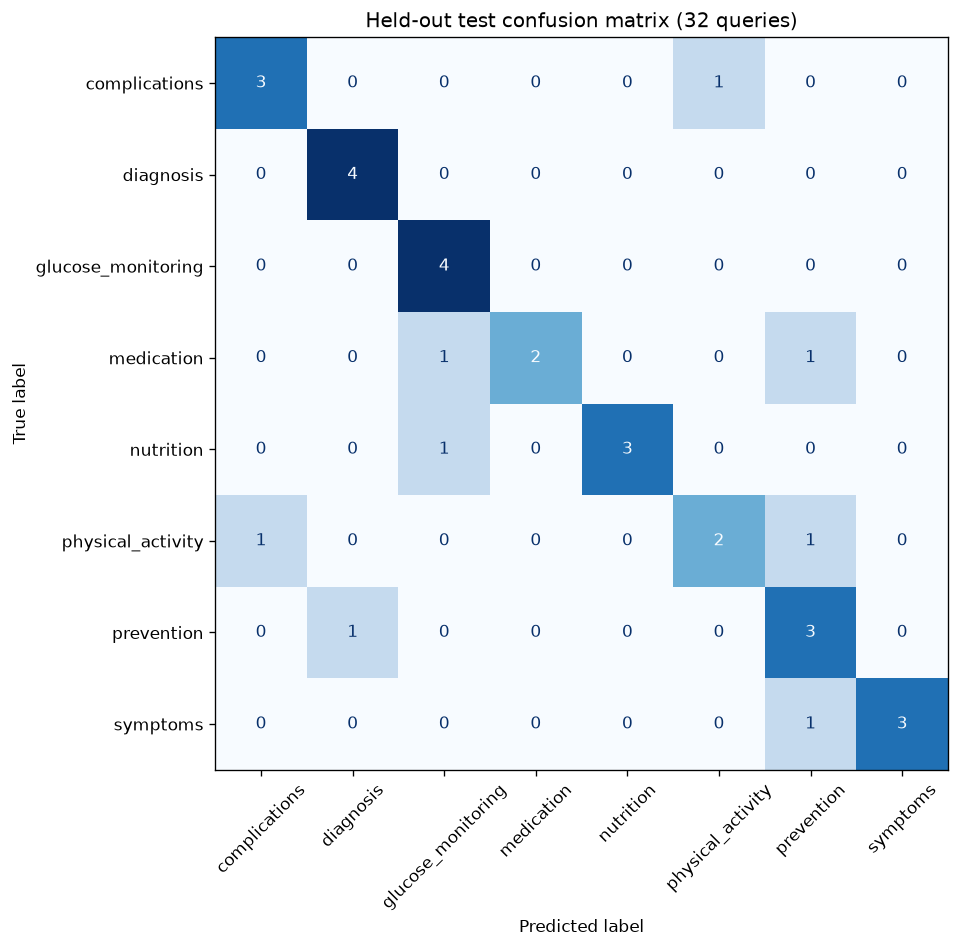

Misclassified test queries: 8


,query,intent,predicted
0,Why is metformin used for type 2 diabetes?,medication,prevention
1,How does exercise help people with diabetes?,physical_activity,prevention
2,How can medicine costs be discussed with the care team?,medication,glucose_monitoring
3,How can I reduce long periods of sitting?,physical_activity,complications
4,What is diabetic neuropathy?,complications,physical_activity
5,Does diabetes make people feel tired?,symptoms,prevention
6,How can I discuss prevention with my doctor?,prevention,diagnosis
7,Explain healthy eating for blood sugar management.,nutrition,glucose_monitoring


In [7]:
train_val, test_df = train_test_split(corpus_df, test_size=0.25,
                                     random_state=SEED, stratify=corpus_df['intent'])
train_df, val_df = train_test_split(train_val, test_size=0.25,
                                   random_state=SEED, stratify=train_val['intent'])
assert (len(train_df), len(val_df), len(test_df)) == (72, 24, 32)
assert set(train_df.index).isdisjoint(test_df.index)
assert set(val_df.index).isdisjoint(test_df.index)

model = Pipeline([
    ('tfidf', TfidfVectorizer(preprocessor=preprocess, lowercase=False,
                            ngram_range=(1, 2), sublinear_tf=True)),
    ('classifier', LogisticRegression(C=5.0, max_iter=2000, random_state=SEED))
])
model.fit(train_df['query'], train_df['intent'])
print('Training / validation / test:', len(train_df), len(val_df), len(test_df))
print('TF-IDF features:', len(model.named_steps['tfidf'].vocabulary_))
predictions = model.predict(test_df['query'])
precision, recall, f1, _ = precision_recall_fscore_support(
    test_df['intent'], predictions, average='macro', zero_division=0)
metrics = pd.DataFrame([{
    'Accuracy': accuracy_score(test_df['intent'], predictions),
    'Macro precision': precision, 'Macro recall': recall, 'Macro F1': f1}])
display(metrics.round(4))
majority_label = train_df['intent'].value_counts().idxmax()
print('Majority-class baseline accuracy:',
      round(float((test_df['intent'] == majority_label).mean()), 4))
print('\nPer-intent classification report:')
print(classification_report(test_df['intent'], predictions, zero_division=0, digits=3))

labels = model.classes_
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(test_df['intent'], predictions, labels=labels,
                                       display_labels=labels, cmap='Blues',
                                       colorbar=False, ax=ax, xticks_rotation=45)
ax.set_title('Held-out test confusion matrix (32 queries)')
plt.tight_layout()
plt.show()

errors = test_df.copy()
errors['predicted'] = predictions
errors = errors[errors['intent'] != errors['predicted']]
print('Misclassified test queries:', len(errors))
display(errors.reset_index(drop=True))

### 6.1 Validation-Based Abstention Thresholds
Threshold selection uses the **validation set only**. For each candidate probability threshold and top-two-score margin, the objective rewards a correct accepted answer and penalizes an incorrect accepted answer twice as much. Ties prefer more correct answers and then a more conservative probability threshold. Rejected cases receive zero reward. The small validation set cannot establish safe deployment thresholds.

This evaluates selective intent classification, separately from emergency and unsupported-query reasoning. Coverage is the proportion of queries accepted; accepted accuracy is reported only if at least one query is accepted.

In [8]:
val_probs = model.predict_proba(val_df['query'])
val_best = val_probs.max(axis=1)
val_margin = np.sort(val_probs, axis=1)[:, -1] - np.sort(val_probs, axis=1)[:, -2]
val_correct = model.classes_[val_probs.argmax(axis=1)] == val_df['intent'].to_numpy()
choices = []
for threshold in [0.25, 0.35, 0.45, 0.55, 0.65]:
    for margin in [0.02, 0.05, 0.10, 0.15]:
        accepted = (val_best >= threshold) & (val_margin >= margin)
        correct = int(np.sum(accepted & val_correct))
        incorrect = int(np.sum(accepted & ~val_correct))
        choices.append({'threshold': threshold, 'margin': margin,
                        'correct_accepted': correct, 'incorrect_accepted': incorrect,
                        'objective': correct - 2 * incorrect})
threshold_results = pd.DataFrame(choices).sort_values(
    ['objective', 'correct_accepted', 'threshold', 'margin'],
    ascending=[False, False, False, False])
best = threshold_results.iloc[0]
CONFIDENCE_THRESHOLD = float(best['threshold'])
MARGIN_THRESHOLD = float(best['margin'])
print('Selected threshold:', CONFIDENCE_THRESHOLD, '| top-two margin:', MARGIN_THRESHOLD)
display(threshold_results.head(5).reset_index(drop=True))

test_probs = model.predict_proba(test_df['query'])
test_margin = np.sort(test_probs, axis=1)[:, -1] - np.sort(test_probs, axis=1)[:, -2]
accepted = (test_probs.max(axis=1) >= CONFIDENCE_THRESHOLD) & (test_margin >= MARGIN_THRESHOLD)
print(f'Test selective coverage: {accepted.mean():.1%} ({accepted.sum()}/{len(accepted)})')
if accepted.any():
    print('Accuracy on accepted test queries:',
          f"{accuracy_score(test_df['intent'].to_numpy()[accepted], predictions[accepted]):.1%}")
else:
    print('No test queries accepted at the selected thresholds.')

Selected threshold: 0.25 | top-two margin: 0.15


,threshold,margin,correct_accepted,incorrect_accepted,objective
0,0.25,0.15,13,0,13
1,0.25,0.05,15,2,11
2,0.25,0.02,15,2,11
3,0.25,0.10,13,1,11
4,0.35,0.15,11,0,11


Test selective coverage: 68.8% (22/32)
Accuracy on accepted test queries: 95.5%


## 7. Domain-Specific Knowledge Base
Each of the eight intents maps to an explanation, a source URL, and a graph concept. Answers are fixed, reviewed summaries, so the model chooses relevant information rather than generating new medical claims. Sources were consulted for this assignment on **22 November 2026**.

The information is intentionally general. Individual glucose targets, treatment changes, diagnostic interpretation and dose calculations must be discussed with a qualified care professional.

In [9]:
KB = {'symptoms': {'answer': 'Possible diabetes symptoms include increased thirst, frequent urination, '
                        'fatigue, blurred vision and unexplained weight loss. Some people have few '
                        'symptoms. Symptoms alone do not confirm diabetes; discuss concerns and '
                        'testing with a clinician.',
              'source': 'https://www.niddk.nih.gov/health-information/diabetes/overview/symptoms-causes',
              'concept': 'Diabetes'},
 'diagnosis': {'answer': 'Clinicians may use A1C, fasting plasma glucose or an oral glucose '
                         'tolerance test; random plasma glucose is used in some situations. '
                         'Diagnosis depends on clinical context and may require confirmation. A '
                         'home meter reading alone is not a formal diagnosis.',
               'source': 'https://www.niddk.nih.gov/health-information/diabetes/overview/tests-diagnosis',
               'concept': 'A1C'},
 'nutrition': {'answer': 'A diabetes eating plan can include vegetables, fiber-rich carbohydrates, '
                         'protein and appropriate portions. Carbohydrates influence glucose. A '
                         'dietitian can help adapt meal choices, timing and portions to your '
                         'treatment plan and preferences.',
               'source': 'https://www.niddk.nih.gov/health-information/diabetes/overview/healthy-living-with-diabetes',
               'concept': 'Nutrition'},
 'physical_activity': {'answer': 'Regular movement, such as walking and resistance exercise, can '
                                 'support diabetes management. Start at an appropriate level and '
                                 'ask your care team about precautions, particularly if using '
                                 'medicines that can cause low glucose or if you have '
                                 'complications.',
                       'source': 'https://www.niddk.nih.gov/health-information/diabetes/overview/healthy-living-with-diabetes',
                       'concept': 'Physical activity'},
 'glucose_monitoring': {'answer': 'A glucose meter checks blood glucose; a CGM tracks glucose '
                                  'trends using a sensor. Record readings and review patterns with '
                                  'your care team. Monitoring times and targets depend on your '
                                  'circumstances and treatment, so follow your individual plan.',
                        'source': 'https://www.niddk.nih.gov/health-information/diabetes/overview/managing-diabetes',
                        'concept': 'Glucose meter'},
 'medication': {'answer': 'Diabetes treatment may involve insulin, tablets or other injectable '
                          'medicines, depending on diabetes type and individual needs. A clinician '
                          'selects treatment considering health conditions, benefits, risks and '
                          'access. Follow the prescription and ask your clinician or pharmacist '
                          'about side effects or missed doses.',
                'source': 'https://www.niddk.nih.gov/health-information/diabetes/overview/insulin-medicines-treatments',
                'concept': 'Medication'},
 'complications': {'answer': 'Diabetes can affect the heart, kidneys, eyes, nerves and feet. '
                             'Managing glucose, blood pressure and cholesterol, together with '
                             'recommended follow-up, may reduce risk. Report foot wounds and new '
                             'symptoms promptly to your care team.',
                   'source': 'https://www.niddk.nih.gov/health-information/diabetes/overview/managing-diabetes',
                   'concept': 'Complications'},
 'prevention': {'answer': 'For people at risk, healthy eating, regular activity and an appropriate '
                          'weight-management plan can help prevent or delay type 2 diabetes. '
                          'Prediabetes and family history are reasons to discuss risk and '
                          'screening with a clinician. Type 1 diabetes has a different cause.',
                'source': 'https://www.niddk.nih.gov/health-information/diabetes/overview/preventing-type-2-diabetes',
                'concept': 'Prediabetes'}}
assert set(KB) == set(CORPUS)
assert all(v['answer'] and v['source'].startswith('https://') for v in KB.values())
display(pd.DataFrame([{'Intent': k, 'Knowledge': v['answer'], 'Source': v['source']}
                      for k, v in KB.items()]))

,Intent,Knowledge,Source
0,symptoms,"Possible diabetes symptoms include increased thirst, frequent urination, fatigue, blur...",https://www.niddk.nih.gov/health-information/diabetes/overview/symptoms-causes
1,diagnosis,"Clinicians may use A1C, fasting plasma glucose or an oral glucose tolerance test; rand...",https://www.niddk.nih.gov/health-information/diabetes/overview/tests-diagnosis
2,nutrition,"A diabetes eating plan can include vegetables, fiber-rich carbohydrates, protein and a...",https://www.niddk.nih.gov/health-information/diabetes/overview/healthy-living-with-dia...
3,physical_activity,"Regular movement, such as walking and resistance exercise, can support diabetes manage...",https://www.niddk.nih.gov/health-information/diabetes/overview/healthy-living-with-dia...
4,glucose_monitoring,A glucose meter checks blood glucose; a CGM tracks glucose trends using a sensor. Reco...,https://www.niddk.nih.gov/health-information/diabetes/overview/managing-diabetes
5,medication,"Diabetes treatment may involve insulin, tablets or other injectable medicines, dependi...",https://www.niddk.nih.gov/health-information/diabetes/overview/insulin-medicines-treat...
6,complications,"Diabetes can affect the heart, kidneys, eyes, nerves and feet. Managing glucose, blood...",https://www.niddk.nih.gov/health-information/diabetes/overview/managing-diabetes
7,prevention,"For people at risk, healthy eating, regular activity and an appropriate weight-managem...",https://www.niddk.nih.gov/health-information/diabetes/overview/preventing-type-2-diabetes


## 8. Reasoning Rules and Integrated Assistant
Rules are applied in priority order; emergencies bypass the classifier and its confidence threshold.

| Rule | Trigger | Action |
|---|---|---|
| R1 | Severe emergency wording | Escalate to local emergency services |
| R2 | Empty input | Ask for a question |
| R3 | Request to calculate or change a medicine dose | Decline individualized dosing and refer to the care team |
| R4 | Low-glucose symptom question | Retrieve a targeted hypoglycemia explanation |
| R5 | Known unsupported topic or no training-vocabulary overlap | Explain the supported scope |
| R6 | Low top intent score or small top-two margin | Ask the user to clarify |
| R7 | Nonzero overlap but weak similarity to every training query | Treat as unsupported rather than forcing an intent |
| R8 | Supported, confident intent | Retrieve KB answer, source and graph context |

The lexical similarity floor is a documented heuristic (0.10); only the confidence and margin thresholds were selected on validation data. Rules are illustrative pattern matchers, not a medical triage system. They cannot reliably resolve every negation, multiple-intent question, language variation or out-of-domain query.

In [10]:
EMERGENCY_SOURCE = 'https://www.cdc.gov/diabetes/about/diabetic-ketoacidosis.html'
HYPO_SOURCE = 'https://www.cdc.gov/diabetes/about/low-blood-sugar-hypoglycemia.html'
SEVERE_PATTERNS = [r'\bunconscious\b', r'\bunresponsive\b', r'\bpassed out\b',
                   r'\bseizure(?:s)?\b', r'\bcannot breathe\b', r"\bcan.t breathe\b",
                   r'\btrouble breathing\b', r'\bchest pain\b',
                   r'\bfruity[ -](?:smelling )?breath\b',
                   r'\bvomiting\b.*\b(?:cannot|can.t) keep\b',
                   r'\b(?:severe|sudden) confusion\b']
UNSUPPORTED_PATTERN = r'\b(?:cancer|tooth|dental infection|migraine|eczema|broken bone|fracture|asthma|antibiotics)\b'
vectorizer = model.named_steps['tfidf']
training_vectors = vectorizer.transform(train_df['query'])

class DiabetesAssistant:
    def _result(self, route, response, intent=None, score=None, source=None, facts=None):
        return {'route': route, 'intent': intent, 'model_score': score,
                'response': response, 'source': source, 'related_facts': facts or []}

    def respond(self, query):
        if not isinstance(query, str):
            return self._result('empty_input', 'Please enter a text question about diabetes.')
        text = query.lower().strip()
        # R1: assessed before ML and before all other topic rules.
        if any(re.search(pattern, text) for pattern in SEVERE_PATTERNS):
            return self._result('emergency',
                'This could be a medical emergency. Contact local emergency services now '
                'or seek immediate emergency care. Do not wait for this chatbot. '
                'If someone is unconscious or unable to swallow, do not give food or drink.',
                source=EMERGENCY_SOURCE)
        if not text:  # R2
            return self._result('empty_input', 'Please enter a question about diabetes care.')
        # R3: general medication information remains available, but dose requests do not.
        dose_request = re.search(
            r'how (?:much|many units)|(?:increase|decrease|double|skip|stop|change|calculate).*'
            r'(?:insulin|metformin|dose|tablet|medication)|what dose|how much insulin', text)
        if dose_request and re.search(r'insulin|metformin|dose|tablet|medic', text):
            return self._result('medication_safety',
                'I cannot calculate or change your medicine dose. Follow your prescribed plan '
                'and contact your clinician or pharmacist for individual advice.',
                source=KB['medication']['source'])
        if re.search(r'low (?:blood )?(?:sugar|glucose)|hypoglyc', text):  # R4
            return self._result('low_glucose_information',
                'Low blood glucose can cause shaking, sweating, hunger or confusion. '
                'Check glucose if possible and follow your agreed low-glucose treatment plan. '
                'Severe confusion, seizures or loss of consciousness require emergency help.',
                intent='symptoms', source=HYPO_SOURCE)
        if re.search(UNSUPPORTED_PATTERN, text):  # R5
            return self._result('unsupported',
                'That topic is outside this diabetes-information assistant. '
                'Please ask a qualified professional about it. I can explain diabetes symptoms, '
                'tests, food, activity, monitoring, medicines, complications or prevention.')
        features = vectorizer.transform([query])
        if features.nnz == 0:
            return self._result('unsupported',
                'I could not match this to diabetes-care information. Please ask a specific diabetes question.')
        probabilities = model.predict_proba([query])[0]
        order = np.argsort(probabilities)[::-1]
        score = float(probabilities[order[0]])
        gap = float(probabilities[order[0]] - probabilities[order[1]])
        intent = str(model.classes_[order[0]])
        if score < CONFIDENCE_THRESHOLD or gap < MARGIN_THRESHOLD:  # R6
            return self._result('low_confidence',
                'I am not sure which diabetes topic you mean. Please specify symptoms, tests, '
                'food, activity, monitoring, medicines, complications or prevention.', score=score)
        similarity = float(cosine_similarity(features, training_vectors).max())
        if similarity < 0.10:  # R7
            return self._result('unsupported',
                'This does not closely match my diabetes knowledge. Please rephrase or consult a professional.',
                score=score)
        entry = KB[intent]  # R8
        return self._result('knowledge_retrieval', entry['answer'], intent, score,
                            entry['source'], related_facts(entry['concept']))

assistant = DiabetesAssistant()
print('Assistant initialized. Supported information intents:', len(KB))

Assistant initialized. Supported information intents: 8


## 9. Required Functional Tests
The following inputs cover each intent, a differently worded question, an unsupported healthcare topic, an ambiguous low-confidence query, and an emergency. These are application demonstrations, separate from held-out classifier metrics. Additional checks cover empty input, a dose request and a low-glucose information question.

The table shows expected and actual behavior rather than assuming every input succeeds. Failed cases remain visible as limitations; functional demonstrations are not used to calculate classifier accuracy.

In [11]:
TEST_CASES = [
    ('Symptoms intent', 'What symptoms and warning signs occur with diabetes?', 'symptoms'),
    ('Diagnosis intent', 'Which laboratory tests diagnose diabetes?', 'diagnosis'),
    ('Nutrition intent', 'How can I plan balanced meals and control carbohydrate portions?', 'nutrition'),
    ('Activity intent', 'How does walking and resistance exercise help diabetes?', 'physical_activity'),
    ('Monitoring intent', 'How do I track daily readings with my glucose meter?', 'glucose_monitoring'),
    ('Medication intent', 'What is the role of metformin and insulin in treatment?', 'medication'),
    ('Complications intent', 'How can diabetes damage nerves kidneys and eyes?', 'complications'),
    ('Prevention intent', 'How can people with prediabetes reduce their future diabetes risk?', 'prevention'),
    ('Different wording', 'Could you explain sensible food choices and meal portions?', 'nutrition'),
    ('Unsupported healthcare', 'Which antibiotics treat a tooth infection?', 'unsupported'),
    ('Low confidence', 'Tell me about diabetes.', 'low_confidence'),
    ('Emergency', 'My father has diabetes and is unconscious.', 'emergency'),
    ('Empty input', '  ', 'empty_input'),
    ('Dose request', 'How many units of insulin should I take?', 'medication_safety'),
    ('Low glucose', 'What are the signs of low blood sugar?', 'low_glucose_information')
]
rows = []
for label, query, expected in TEST_CASES:
    result = assistant.respond(query)
    actual = result['intent'] if result['route'] == 'knowledge_retrieval' else result['route']
    rows.append({'Test': label, 'Query': query, 'Expected': expected,
                 'Actual': actual, 'Pass': actual == expected,
                 'Score': result['model_score']})
results_df = pd.DataFrame(rows)
display(results_df)
print('Functional checks passed:', results_df['Pass'].sum(), '/', len(results_df))

for label, query, _ in TEST_CASES:
    answer = assistant.respond(query)
    print('\n' + label + ' | Query: ' + repr(query))
    print('Route:', answer['route'], '| Intent:', answer['intent'])
    print('Assistant:', answer['response'])
    if answer['source']:
        print('Source:', answer['source'])

assert assistant.respond('My friend is unconscious; what insulin dose?')['route'] == 'emergency'
assert assistant.respond('Which antibiotics treat a tooth infection?')['route'] == 'unsupported'
assert assistant.respond('How many units of insulin should I take?')['route'] == 'medication_safety'
assert assistant.respond('')['route'] == 'empty_input'
print('\nRule-priority and safety checks passed.')

,Test,Query,Expected,Actual,Pass,Score
0,Symptoms intent,What symptoms and warning signs occur with diabetes?,symptoms,symptoms,True,0.649137
1,Diagnosis intent,Which laboratory tests diagnose diabetes?,diagnosis,diagnosis,True,0.717516
2,Nutrition intent,How can I plan balanced meals and control carbohydrate portions?,nutrition,nutrition,True,0.807593
3,Activity intent,How does walking and resistance exercise help diabetes?,physical_activity,physical_activity,True,0.453180
4,Monitoring intent,How do I track daily readings with my glucose meter?,glucose_monitoring,glucose_monitoring,True,0.438276
5,Medication intent,What is the role of metformin and insulin in treatment?,medication,medication,True,0.566530
6,Complications intent,How can diabetes damage nerves kidneys and eyes?,complications,complications,True,0.432567
7,Prevention intent,How can people with prediabetes reduce their future diabetes risk?,prevention,prevention,True,0.794239
8,Different wording,Could you explain sensible food choices and meal portions?,nutrition,nutrition,True,0.550953
9,Unsupported healthcare,Which antibiotics treat a tooth infection?,unsupported,unsupported,True,NaN


Functional checks passed: 15 / 15

Symptoms intent | Query: 'What symptoms and warning signs occur with diabetes?'
Route: knowledge_retrieval | Intent: symptoms
Assistant: Possible diabetes symptoms include increased thirst, frequent urination, fatigue, blurred vision and unexplained weight loss. Some people have few symptoms. Symptoms alone do not confirm diabetes; discuss concerns and testing with a clinician.
Source: https://www.niddk.nih.gov/health-information/diabetes/overview/symptoms-causes

Diagnosis intent | Query: 'Which laboratory tests diagnose diabetes?'
Route: knowledge_retrieval | Intent: diagnosis
Assistant: Clinicians may use A1C, fasting plasma glucose or an oral glucose tolerance test; random plasma glucose is used in some situations. Diagnosis depends on clinical context and may require confirmation. A home meter reading alone is not a formal diagnosis.
Source: https://www.niddk.nih.gov/health-information/diabetes/overview/tests-diagnosis

Nutrition intent | Query: 

## 10. Interactive Colab Interface
Run the next cell after training. Type a question and click **Ask** repeatedly; responses remain visible as a conversation. Knowledge answers show their source and relevant graph facts. The interface does not transmit queries to an external service or write conversation history to disk.

Colab may require its custom widget manager. The small compatibility block enables it only when running in Colab. The notebook includes a saved text demonstration, while the live widget is created when this cell is rerun.

In [12]:
try:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()
except ImportError:
    pass

query_box = widgets.Textarea(
    placeholder='Ask a diabetes-care information question...',
    layout=widgets.Layout(width='100%', height='75px'))
ask_button = widgets.Button(description='Ask', button_style='primary')
clear_button = widgets.Button(description='Clear history')
chat_output = widgets.Output(layout=widgets.Layout(border='1px solid #cbd5e1', padding='10px'))

def on_ask(_):
    query = query_box.value
    result = assistant.respond(query)
    with chat_output:
        display(HTML('<p><b>You:</b> ' + html.escape(query or '(empty)') + '</p>'))
        display(HTML('<p><b>Assistant:</b> ' + html.escape(result['response']) + '</p>'))
        details = 'Route: ' + result['route']
        if result['intent']:
            details += ' | ' + INTENT_PATH[result['intent']]
        if result['model_score'] is not None:
            details += f" | Model score: {result['model_score']:.3f}"
        display(HTML('<small>' + html.escape(details) + '</small>'))
        if result['source']:
            display(HTML('<p><a href="' + html.escape(result['source'], quote=True) +
                         '" target="_blank">Read the healthcare source</a></p>'))
        for fact in result['related_facts']:
            print('Knowledge graph:', fact)
        print('—' * 50)
    query_box.value = ''

def on_clear(_):
    chat_output.clear_output()

ask_button.on_click(on_ask)
clear_button.on_click(on_clear)
display(widgets.VBox([widgets.HTML('<h3>Diabetes Care Information Assistant</h3>'
                                  '<p>General information only; no diagnosis or dose calculation.</p>'),
                      query_box, widgets.HBox([ask_button, clear_button]), chat_output]))
print('Enter a question above and click Ask. You can submit multiple queries.')

Enter a question above and click Ask. You can submit multiple queries.


In [13]:
# Verify repeated submissions through the same interface callback.
for demo_query in ['How do I monitor my blood glucose at home?',
                   'Which antibiotics treat a tooth infection?']:
    query_box.value = demo_query
    ask_button.click()
    assert query_box.value == '', 'The Ask callback did not finish.'
print('Interactive callback check passed: two consecutive queries submitted.')

Interactive callback check passed: two consecutive queries submitted.


In [14]:
def run_console():
    print('Diabetes Care Information Assistant. Type exit to end.')
    while True:
        query = input('You: ').strip()
        if query.lower() in {'exit', 'quit'}:
            print('Session ended.')
            break
        result = assistant.respond(query)
        print('Assistant:', result['response'])
        if result['source']:
            print('Source:', result['source'])

RUN_CONSOLE = False  # Set True and run this cell if you prefer repeated text input.
if RUN_CONSOLE:
    run_console()

## 11. Results, Limitations and Requirement Coverage
The metric table, confusion matrix and error table above report the actual held-out run. The assistant's end-to-end behavior is also affected by its rules and abstention thresholds, so classifier accuracy alone does not measure response safety or usefulness.

**Limitations:** The corpus is small, synthetic and English-only. Train/test separation prevents exact query leakage, but shared wording may still make evaluation optimistic. Model scores are not calibrated medical confidence. The rule list can over-escalate hypothetical or negated emergencies and can miss emergencies phrased differently. Unsupported-topic detection is incomplete. Fixed answers cannot tailor care to a person, and sources require periodic review. More diverse independently labelled queries, clinician review, user testing and careful clinical governance would be needed before real healthcare use.

| Requirement | Implementation |
|---|---|
| ≥40 labelled queries, ≥5 intents | Section 2: 128 queries, 8 intents |
| ≥4 major taxonomy categories, ≥2 children each | Section 3: 4 categories, 2 children each |
| ≥8 concepts, ≥10 relationships | Section 4: 15 concepts, 16 relations |
| Lowercase, tokenize, remove stopwords, lemmatize | Section 5 |
| TF-IDF and trained classifier | Section 6: word TF-IDF + Logistic Regression |
| Accuracy, precision, recall, F1 and confusion matrix | Section 6: held-out results and errors |
| Knowledge base for every intent | Section 7: 8 source-backed entries |
| ≥5 reasoning rules | Section 8: 8 rules including emergency, uncertainty and unsupported handling |
| Integrated assistant | Section 8: `DiabetesAssistant.respond()` |
| Interactive Colab interface with multiple queries | Section 10: widgets and console fallback; upload/run instructions in Section 1 |
| Required test scenarios | Section 9: every intent, paraphrase, unsupported, low confidence and emergency |

**Conclusion:** The prototype combines a labelled intent model with an explicit knowledge structure, source-backed retrieval and rule-based reasoning. It demonstrates the requested cognitive-assistant workflow while keeping uncertainty and unsupported requests visible.

## References
Healthcare summaries and reasoning rules:
- [NIDDK: Symptoms and causes of diabetes](https://www.niddk.nih.gov/health-information/diabetes/overview/symptoms-causes).
- [NIDDK: Diabetes tests and diagnosis](https://www.niddk.nih.gov/health-information/diabetes/overview/tests-diagnosis).
- [NIDDK: Healthy living with diabetes](https://www.niddk.nih.gov/health-information/diabetes/overview/healthy-living-with-diabetes).
- [NIDDK: Managing diabetes](https://www.niddk.nih.gov/health-information/diabetes/overview/managing-diabetes).
- [NIDDK: Insulin, medicines and other diabetes treatments](https://www.niddk.nih.gov/health-information/diabetes/overview/insulin-medicines-treatments).
- [NIDDK: Preventing type 2 diabetes](https://www.niddk.nih.gov/health-information/diabetes/overview/preventing-type-2-diabetes).
- [CDC: Diabetic ketoacidosis](https://www.cdc.gov/diabetes/about/diabetic-ketoacidosis.html).
- [CDC: Low blood sugar](https://www.cdc.gov/diabetes/about/low-blood-sugar-hypoglycemia.html).
- [NHS: Low blood sugar](https://www.nhs.uk/conditions/low-blood-sugar-hypoglycaemia/), including unconscious-person precautions.

Implementation references:
- [scikit-learn: TF-IDF vectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).
- [NLTK: WordNet lemmatizer](https://www.nltk.org/api/nltk.stem.wordnet.html).
- [Google Colab: Widget examples](https://colab.research.google.com/notebooks/widgets.ipynb).
- Supplied assignment brief: *UCS420_Assignment10.pdf*.